![](img/banner.png)


# Bias–Variance Tradeoff

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

This chapter follows Hastie, Tibshirani and Friedman, *The Elements of Statistical
Learning* (2nd ed.), **Sections 7.2–7.5**. Equation numbers in parentheses, e.g. (7.9),
are the numbers of that book.

## Where this chapter sits

In [Model Evaluation and Model Selection](Model-Evaluation.ipynb) we learned *how* to
estimate the error of a model — hold-out, cross-validation, bootstrap — and how to
compare models with it. Here we ask *why* the error curve has a U shape, and what the
two competing terms in it are. This is the theory behind:

* choosing model complexity (polynomial degree, number of neighbors, network width, …);
* reading regularization (ridge, lasso, early stopping) as an explicit bias–variance dial;
* the claim "more data beats a cleverer algorithm" ([Introduction](Introduction.ipynb))
  and the double-descent phenomenon.

**Learning objectives.** By the end you should be able to

1. distinguish *conditional test error*, *expected test error* and *training error* (ESL 7.2);
2. derive and interpret $\mathrm{Err}(x_0)=\sigma_\varepsilon^2+\mathrm{Bias}^2+\mathrm{Var}$ (ESL 7.3);
3. measure bias$^2$ and variance experimentally for a family of models;
4. explain why the additive decomposition **fails** for 0–1 loss;
5. explain why the training error is optimistic, and what $C_p$ and AIC add to it (ESL 7.4–7.5).

## 1. Three different errors

Let $\mathcal{T}=\{(x_1,y_1),\dots,(x_N,y_N)\}$ be the training set, $\hat f$ the fitted
model, and $L$ a loss function (squared error for regression; 0–1 loss or
$-2\log\hat p$ for classification). ESL distinguishes three quantities:

$$
\begin{aligned}
\text{test (generalization) error:}\quad & \mathrm{Err}_{\mathcal T}=E_{X^0,Y^0}\big[L(Y^0,\hat f(X^0))\,\big|\,\mathcal T\big] && (7.2)\\
\text{expected prediction error:}\quad & \mathrm{Err}=E_{\mathcal T}\big[\mathrm{Err}_{\mathcal T}\big] && (7.3)\\
\text{training error:}\quad & \overline{\mathrm{err}}=\frac{1}{N}\sum_{i=1}^{N}L\big(y_i,\hat f(x_i)\big) && (7.4)
\end{aligned}
$$

| quantity | what is random | can we estimate it? |
|---|---|---|
| $\mathrm{Err}_{\mathcal T}$ | the new test pair $(X^0,Y^0)$; $\hat f$ is *fixed* | hard: it is conditional on the one training set we happen to have |
| $\mathrm{Err}$ | test pair **and** the training set | yes — this is what CV, bootstrap and AIC/$C_p$ estimate |
| $\overline{\mathrm{err}}$ | nothing left to average over | computable, but **biased downward** |

The picture to remember is ESL Figure 7.1: as model complexity grows, the training error
decreases monotonically — it can be driven to zero — while the expected test error is
**U-shaped**. The gap $\mathrm{Err}-\overline{\mathrm{err}}$ is the *optimism* of the
training error, and Section 7 makes it quantitative.

## 2. The bias–variance decomposition

Assume the data are generated as

$$
Y=f(X)+\varepsilon,\qquad E[\varepsilon]=0,\qquad \operatorname{Var}(\varepsilon)=\sigma_\varepsilon^{2},
$$

and fix an evaluation point $x_0$. The expected squared prediction error of a fitted
model $\hat f$ is

$$
\begin{aligned}
\mathrm{Err}(x_0)
&=E\big[(Y-\hat f(x_0))^2\,\big|\,X=x_0\big]\\
&=E\big[(f(x_0)+\varepsilon-\hat f(x_0))^2\big]\\
&=E\big[(f(x_0)-\hat f(x_0))^2\big] \;+\; 2\,\underbrace{E[\varepsilon]}_{=\,0}\,E\big[f(x_0)-\hat f(x_0)\big] \;+\; \underbrace{E[\varepsilon^{2}]}_{=\,\sigma_\varepsilon^{2}}\\
&=\Big(f(x_0)-E\hat f(x_0)\Big)^{2}\;+\;E\Big[\big(\hat f(x_0)-E\hat f(x_0)\big)^{2}\Big]\;+\;\sigma_\varepsilon^{2}
\end{aligned}
$$

The cross term vanishes because the test noise $\varepsilon$ is independent of the fitted
model and has zero mean. In the book's notation,

$$
\boxed{\;\mathrm{Err}(x_0)=\underbrace{\sigma_\varepsilon^{2}}_{\text{irreducible}}
+\underbrace{\mathrm{Bias}^2\!\big(\hat f(x_0)\big)}_{\text{squared bias}}
+\underbrace{\operatorname{Var}\big(\hat f(x_0)\big)}_{\text{variance}}\;}
\qquad (7.9)
$$

All expectations are over **training sets** $\mathcal T$: the point $x_0$ is fixed, and
$\hat f$ is random because $\mathcal T$ is random.

### How to read (7.9)

* **Irreducible error.** $\sigma_\varepsilon^2$ is a floor: no model, however clever, can
  go below it. It is the part of $Y$ that is not a function of $X$.
* **Squared bias.** How far the *average* prediction over all training sets is from the
  truth. It measures *systematic* misfit: the family is too rigid, or the fit is
  intentionally restricted (shrinkage).
* **Variance.** How much the prediction moves when the training set changes. It measures
  *sensitivity*: a flexible model that chases noise has large variance.
* **The trade-off.** More complexity usually decreases bias and increases variance;
  minimizing their sum gives the sweet spot of Figure 7.1.
* **One fit only.** For the model we actually fitted we observe a single draw, not the
  average $E\hat f$. This is exactly why bias and variance cannot be measured on real data
  and we use cross-validation instead; the experiments below simulate many training sets
  to make the decomposition visible.

### 2.1 Two special cases worth remembering

**$k$-nearest-neighbors regression** (fixed design, randomness only in the $y_i$):

$$
\mathrm{Err}(x_0)=\sigma_\varepsilon^{2}+\left[f(x_0)-\frac{1}{k}\sum_{\ell=1}^{k}f\big(x_{(\ell)}\big)\right]^{2}+\frac{\sigma_\varepsilon^{2}}{k}
\qquad(7.10)
$$

Here $k$ is *inverse* complexity: variance falls like $1/k$, while bias grows because we
average $f$ over a wider neighborhood.

**Least-squares linear model** $\hat f_p(x)=x^{T}\hat\beta$ with $p$ parameters:

$$
\mathrm{Err}(x_0)=\sigma_\varepsilon^{2}+\big[f(x_0)-E\hat f_p(x_0)\big]^{2}+\lVert h(x_0)\rVert^{2}\sigma_\varepsilon^{2},
\qquad h(x_0)=X(X^{T}X)^{-1}x_0 \qquad(7.11)
$$

and averaged over the training points the variance term is exactly $p\sigma_\varepsilon^{2}/N$:

$$
\frac{1}{N}\sum_{i=1}^{N}\mathrm{Err}(x_i)=\sigma_\varepsilon^{2}+\frac{1}{N}\sum_{i=1}^{N}\big[f(x_i)-E\hat f(x_i)\big]^{2}+\frac{p}{N}\sigma_\varepsilon^{2}.
\qquad(7.12)
$$

For linear models, **complexity = number of parameters**, and variance grows linearly with
it. Ridge regression keeps the form of (7.11) but replaces $h(x_0)$ by
$h_\alpha(x_0)=X(X^{T}X+\alpha I)^{-1}x_0$: variance shrinks, and an *estimation bias*
appears. Section 5 shows this experimentally.

## 3. Experiment 1 — model complexity in polynomial regression

This is the experiment behind ESL Figure 7.1. The design is

* true function $f(x)=\sin(\pi x)$ on $[-1,1]$ with additive Gaussian noise, $\sigma_\varepsilon=0.5$;
* $25$ observations per simulated dataset; $1000$ simulated datasets — the only way to
  *see* an expectation over $\mathcal T$;
* polynomial fits of degree $1,\dots,12$ by ordinary least squares;
* evaluation on a fixed dense grid, so we measure the extra-sample error of (7.2)
  rather than the error at five held-out points.

For every degree we then have the three ingredients of (7.9): the average prediction, its
spread around that average, and the average squared error.

In [1]:
%matplotlib inline

import warnings
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

In [2]:
def f(x):
    '''True regression function.'''
    return np.sin(x * np.pi)


def squared_error(pred, actual):
    return (pred - actual) ** 2

In [3]:
np.random.seed(120)

N_OBS = 25                   # observations per simulated dataset
N_DATASETS = 1000            # number of training sets T
NOISE_STD = 0.5              # sigma_eps
PERCENT_TRAIN = 0.8
DEGREES = np.arange(1, 13)   # model complexity: polynomial degree

n_train = int(np.ceil(N_OBS * PERCENT_TRAIN))   # 20
SIGMA2 = NOISE_STD ** 2

# evaluation grid: bias and variance are computed pointwise, then averaged
x_grid = np.linspace(-1, 1, 200)
f_grid = f(x_grid)

In [4]:
# one fixed design: 25 inputs, shuffled, split into 20 train / 5 test
x_all = np.random.permutation(np.linspace(-1, 1, N_OBS))
x_train, x_test = x_all[:n_train], x_all[n_train:]

theta_hat = defaultdict(list)      # fitted coefficients, per dataset
pred_grid = defaultdict(list)      # predictions on the evaluation grid
train_err = defaultdict(list)      # training error  = err
grid_err = defaultdict(list)       # test error on the grid = Err_T

In [5]:
with warnings.catch_warnings():
    # high degrees on 20 points are numerically ill-conditioned; the warning is harmless
    warnings.simplefilter("ignore")

    for dataset in range(N_DATASETS):

        # one training set: fresh noise on the fixed design
        y_train = f(x_train) + NOISE_STD * np.random.randn(n_train)

        # the test sample of this replication: fresh noise on the fixed grid
        y_grid = f_grid + NOISE_STD * np.random.randn(x_grid.size)

        for degree in DEGREES:

            beta = np.polyfit(x_train, y_train, degree)
            theta_hat[degree].append(beta)

            # prediction at the training inputs -> training error (7.4)
            y_hat_train = np.polyval(beta, x_train)
            train_err[degree].append(np.mean(squared_error(y_hat_train, y_train)))

            # prediction on the grid -> test error (7.2)
            y_hat_grid = np.polyval(beta, x_grid)
            pred_grid[degree].append(y_hat_grid)
            grid_err[degree].append(np.mean(squared_error(y_hat_grid, y_grid)))

### 3.1 One fit per complexity

Before averaging anything, look at individual fits. Low degrees cannot bend enough
(bias); high degrees pass close to the noisy points and swing wildly between samples
(variance).

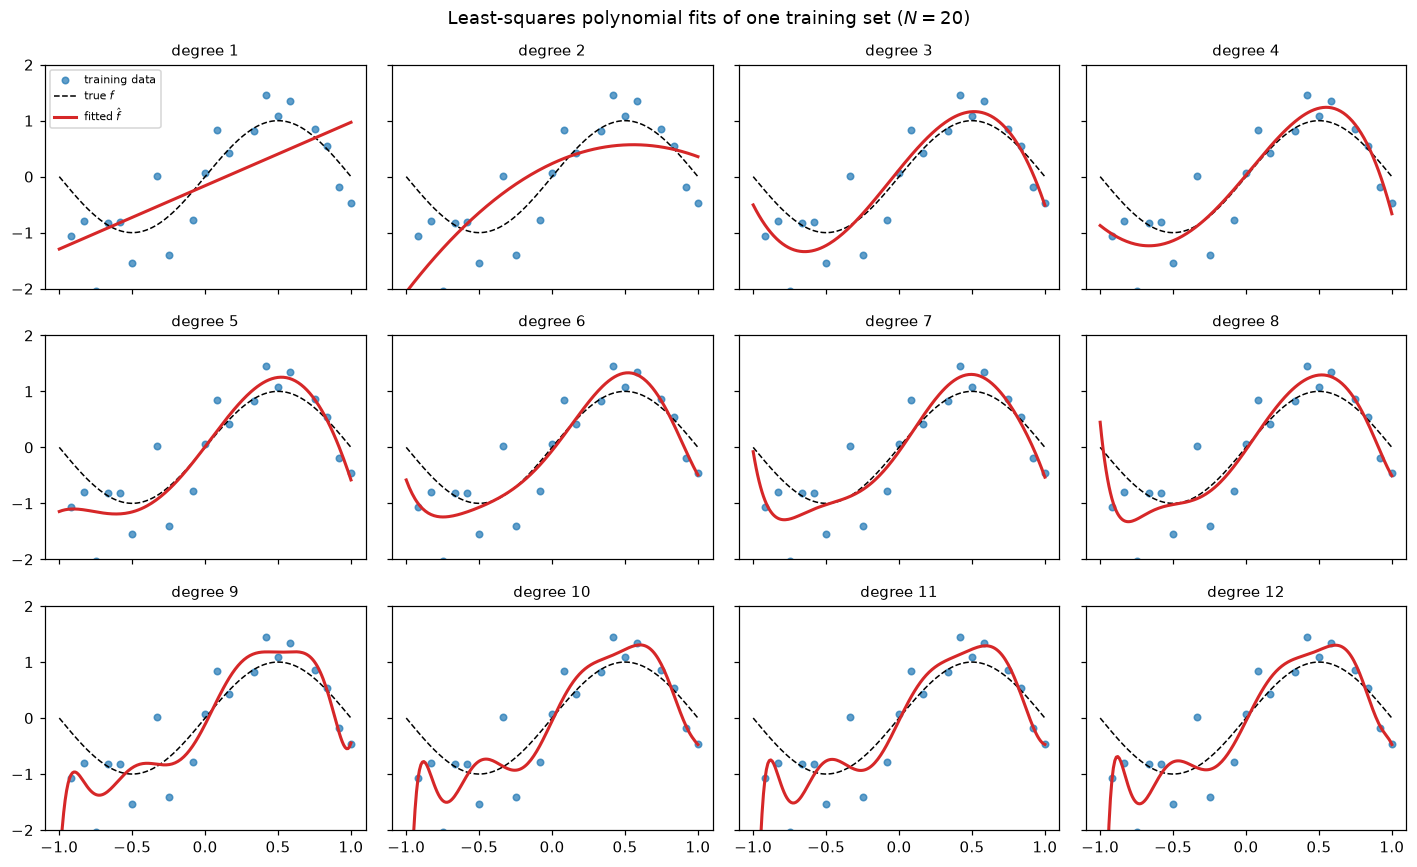

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharex=True, sharey=True)

for ax, degree in zip(axes.ravel(), DEGREES):
    ax.scatter(x_train, y_train, s=18, color="tab:blue", alpha=0.7, label="training data")
    ax.plot(x_grid, f_grid, "k--", lw=1, label="true $f$")
    ax.plot(x_grid, pred_grid[degree][-1], color="tab:red", lw=2, label=r"fitted $\hat f$")
    ax.set_title(f"degree {degree}", fontsize=10)
    ax.set_ylim(-2, 2)

axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle(r"Least-squares polynomial fits of one training set ($N=20$)", y=0.98)
fig.tight_layout()

### 3.2 Bias$^2$, variance and expected test error

For each degree, pointwise on the grid,

$$
\widehat{\mathrm{Bias}}^2(x_0)=\Big(\overline{\hat f}(x_0)-f(x_0)\Big)^2,
\qquad
\widehat{\mathrm{Var}}(x_0)=\frac{1}{B}\sum_{b=1}^{B}\Big(\hat f_b(x_0)-\overline{\hat f}(x_0)\Big)^2,
$$

with $B=1000$ replications and $\overline{\hat f}$ the average over replications. We then
average over the grid. The test error is
$\frac{1}{B}\sum_b\frac{1}{G}\sum_g\big(y^{(b)}_g-\hat f_b(x_g)\big)^2$, with fresh
responses $y^{(b)}_g$ in every replication.

In [7]:
bias_sq, variance, expected_err, mean_train_err = [], [], [], []

for degree in DEGREES:
    P = np.array(pred_grid[degree])           # shape (B, G)
    mean_pred = P.mean(axis=0)                # E_T f_hat, pointwise
    bias_sq.append(np.mean((mean_pred - f_grid) ** 2))
    variance.append(np.mean((P - mean_pred) ** 2))
    expected_err.append(np.mean(grid_err[degree]))
    mean_train_err.append(np.mean(train_err[degree]))

best = DEGREES[int(np.argmin(expected_err))]
print(f"minimum expected test error at degree {best} "
      f"({min(expected_err):.3f});  irreducible noise sigma^2 = {SIGMA2:.3f}")

minimum expected test error at degree 3 (0.306);  irreducible noise sigma^2 = 0.250


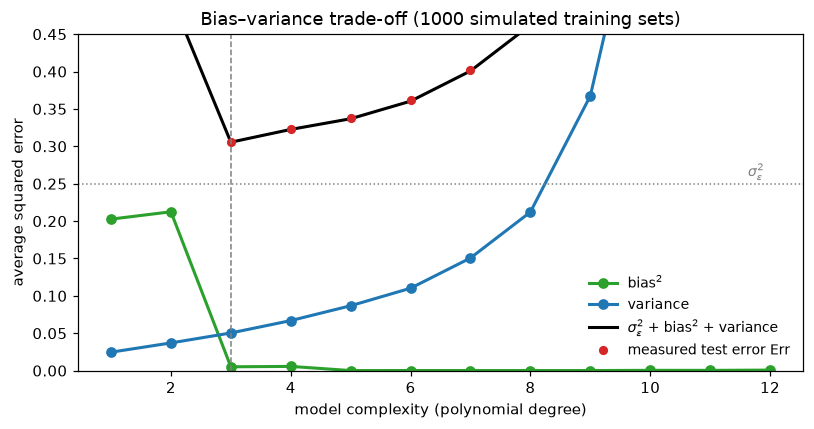

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4))

ax.plot(DEGREES, bias_sq, "o-", color="tab:green", lw=2, label=r"bias$^2$")
ax.plot(DEGREES, variance, "o-", color="tab:blue", lw=2, label="variance")
ax.plot(DEGREES, np.add(bias_sq, variance) + SIGMA2, "-", color="black", lw=2,
        label=r"$\sigma_\varepsilon^2$ + bias$^2$ + variance")
ax.plot(DEGREES, expected_err, "o", color="tab:red", ms=5,
        label=r"measured test error $\mathrm{Err}$")
ax.axhline(SIGMA2, color="gray", ls=":", lw=1)
ax.axvline(best, color="gray", ls="--", lw=1)
ax.annotate(r"$\sigma_\varepsilon^2$", (12, SIGMA2), textcoords="offset points",
            xytext=(-4, 5), ha="right", fontsize=9, color="gray")

ax.set_xlabel("model complexity (polynomial degree)")
ax.set_ylabel("average squared error")
ax.set_ylim(0, 0.45)
ax.legend(frameon=False, fontsize=9)
ax.set_title(r"Bias–variance trade-off (1000 simulated training sets)")
fig.tight_layout()

In [9]:
print(f"{'degree':>7}{'bias^2':>10}{'var':>10}{'sum+noise':>12}{'test err':>11}{'train err':>11}")
for i, degree in enumerate(DEGREES):
    total = SIGMA2 + bias_sq[i] + variance[i]
    print(f"{degree:7d}{bias_sq[i]:10.4f}{variance[i]:10.4f}{total:12.4f}"
          f"{expected_err[i]:11.4f}{mean_train_err[i]:11.4f}")

 degree    bias^2       var   sum+noise   test err  train err
      1    0.2026    0.0247      0.4773     0.4783     0.4226
      2    0.2124    0.0371      0.4995     0.5009     0.3980
      3    0.0051    0.0504      0.3055     0.3061     0.2047
      4    0.0057    0.0670      0.3226     0.3235     0.1912
      5    0.0001    0.0868      0.3369     0.3381     0.1741
      6    0.0002    0.1102      0.3604     0.3618     0.1614
      7    0.0001    0.1507      0.4008     0.4018     0.1487
      8    0.0001    0.2121      0.4623     0.4639     0.1357
      9    0.0001    0.3675      0.6176     0.6199     0.1230
     10    0.0004    0.7140      0.9644     0.9668     0.1108
     11    0.0004    1.5526      1.8030     1.8096     0.0984
     12    0.0007    4.6811      4.9318     4.9369     0.0862


### Reading the experiment

* The black curve ($\sigma_\varepsilon^2+$bias$^2+$variance) and the red dots (directly
  measured test error) agree to within about $0.005$ for every degree. That is (7.9) in
  numbers: the decomposition is an identity, not an approximation.
* The best degree is $3$, with expected test error $0.306$. The floor is
  $\sigma_\varepsilon^2=0.25$, and the excess $0.056$ is almost entirely **variance**
  ($0.050$); bias$^2$ is already $0.005$.
* From there the two terms move in opposite directions. Variance grows by two orders of
  magnitude, to $1.55$ at degree $11$, because each extra coefficient is estimated from
  the same 20 noisy points. Bias$^2$ collapses to $\approx10^{-4}$: a high-degree
  polynomial can represent a sine essentially exactly.
* The training-error column falls monotonically, from $0.42$ to $0.086$, while the test
  error *rises* from $0.31$ to $4.94$. At degree 12 the model is 55 times worse than at
  degree 3 although it fits the training data five times better — that is the optimism of
  Section 7.
* Choose by the test-error curve, never by the training-error curve; and note that the
  best degree is *not* the "exact" degree of the generating function, because the
  coefficients themselves must be estimated.

## 4. Experiment 2 — complexity through $k$ in $k$-NN regression

Equation (7.10) gives a second, cleaner view of the trade-off: the variance is exactly
$\sigma_\varepsilon^2/k$ (we average $k$ independent noises), while the bias is the gap
between $f(x_0)$ and the average of $f$ over the $k$ nearest neighbors. As $k$ grows the
neighborhood widens, so bias grows and variance shrinks.

We mimic the left panels of ESL Figure 7.3: a fixed design of 100 inputs, a smooth
regression function, and $k$ from 1 to 51.

In [10]:
from sklearn.neighbors import KNeighborsRegressor

rng = np.random.default_rng(0)

n_kn, n_grid, n_rep = 100, 200, 200
x_kn = np.linspace(0, 1, n_kn)
x0 = np.linspace(0, 1, n_grid)
g = np.sin(2 * np.pi * x0)          # true function at the evaluation points
noise = 0.3

ks = np.array([1, 3, 5, 7, 9, 13, 17, 21, 27, 33, 41, 51])
preds = np.empty((n_rep, n_grid))
bias_k, var_k, err_k = [], [], []

for k in ks:
    total_err = 0.0
    for r in range(n_rep):
        y = np.sin(2 * np.pi * x_kn) + noise * rng.standard_normal(n_kn)
        model = KNeighborsRegressor(n_neighbors=int(k)).fit(x_kn[:, None], y)
        preds[r] = model.predict(x0[:, None])
        y0 = g + noise * rng.standard_normal(n_grid)      # fresh test responses
        total_err += np.mean((y0 - preds[r]) ** 2)

    mean_pred = preds.mean(axis=0)
    bias_k.append(np.mean((mean_pred - g) ** 2))
    var_k.append(np.mean((preds - mean_pred) ** 2))
    err_k.append(total_err / n_rep)

print(f"{'k':>4}{'bias^2':>9}{'var':>9}{'sum+noise':>12}{'test err':>10}")
for i, k in enumerate(ks):
    print(f"{k:4d}{bias_k[i]:9.4f}{var_k[i]:9.4f}"
          f"{noise**2 + bias_k[i] + var_k[i]:12.4f}{err_k[i]:10.4f}")

   k   bias^2      var   sum+noise  test err
   1   0.0006   0.0906      0.1813    0.1821
   3   0.0004   0.0296      0.1200    0.1212
   5   0.0005   0.0178      0.1083    0.1097
   7   0.0011   0.0130      0.1042    0.1034
   9   0.0024   0.0098      0.1022    0.1014
  13   0.0062   0.0071      0.1033    0.1032
  17   0.0132   0.0052      0.1084    0.1092
  21   0.0219   0.0043      0.1162    0.1157
  27   0.0382   0.0034      0.1316    0.1318
  33   0.0532   0.0025      0.1457    0.1465
  41   0.0677   0.0021      0.1598    0.1603
  51   0.0856   0.0017      0.1773    0.1776


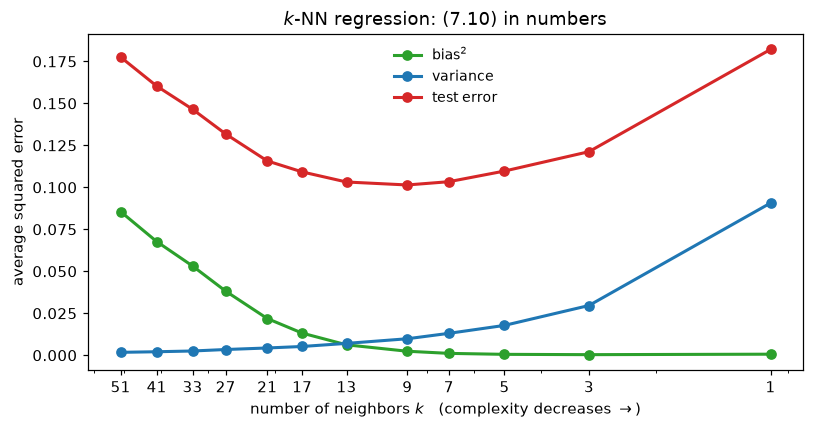

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))

ax.plot(ks, bias_k, "o-", color="tab:green", lw=2, label=r"bias$^2$")
ax.plot(ks, var_k, "o-", color="tab:blue", lw=2, label="variance")
ax.plot(ks, err_k, "o-", color="tab:red", lw=2, label="test error")
ax.set_xscale("log")
ax.set_xticks(ks)
ax.set_xticklabels([str(k) for k in ks])
ax.invert_xaxis()          # complexity decreases to the right, as in ESL Fig 7.3
ax.set_xlabel(r"number of neighbors $k$   (complexity decreases $\rightarrow$)")
ax.set_ylabel("average squared error")
ax.legend(frameon=False, fontsize=9)
ax.set_title(r"$k$-NN regression: (7.10) in numbers")
fig.tight_layout()

The numbers follow (7.10) almost exactly: at $k=1$ the variance is $0.0906$, which is
$\sigma_\varepsilon^2=0.09$; at $k=51$ it is $0.0017$, against the predicted
$0.09/51=0.0018$. Meanwhile bias$^2$ rises from $0.0006$ to $0.086$, and the sum
reproduces the measured test error. The minimum is at $k=9$, again a compromise, and
again unrelated to the smallest training error. For a *fixed* $N$ the only knob is $k$ —
and that is exactly the situation of any other hyperparameter (depth, width, number of
trees, $\alpha$).

## 5. Model bias versus estimation bias: ridge regression

For a restricted family such as ridge, ESL splits the bias of (7.9) into two parts. Let

$$
\beta_*=\arg\min_\beta E\big[f(X)-X^{T}\beta\big]^{2}
\qquad(7.13)
$$

be the best linear approximation to the truth. Then

$$
E_{x_0}\big[f(x_0)-E\hat f_\alpha(x_0)\big]^{2}
=\underbrace{E_{x_0}\big[f(x_0)-x_0^{T}\beta_*\big]^{2}}_{\text{average model bias}}
+\underbrace{E_{x_0}\big[x_0^{T}\beta_*-x_0^{T}\hat\beta_\alpha\big]^{2}}_{\text{average estimation bias}}
\qquad(7.14)
$$

* For ordinary least squares the estimation bias is **zero** (OLS is unbiased inside the
  linear family), but its variance can be large.
* Ridge ($\alpha>0$) shrinks the coefficients: it *adds* estimation bias and *removes*
  variance. It pays off whenever the variance drop exceeds the bias increase.
* Only a richer model class (interactions, basis expansions) can reduce the **model bias**.

The schematic to keep in mind is ESL Figure 7.2: truth, model space, the "closest fit"
$x_0^{T}\beta_*$, the yellow variance ball around it, and the shrunken fit pulled towards
the origin. Let us measure that picture with a 12th-degree polynomial basis and only
25 observations — a setting in which the least-squares variance is large enough for
shrinkage to pay off.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(1)

n_r, n_grid_r, n_rep_r = 25, 200, 200
x_r = np.linspace(0, 1, n_r)
x0_r = np.linspace(0, 1, n_grid_r)
f_r = np.sin(2 * np.pi * x0_r)
sigma = 0.3

poly = PolynomialFeatures(degree=12, include_bias=False)
Phi = poly.fit_transform(x_r[:, None])
Phi0 = poly.transform(x0_r[:, None])

alphas = np.logspace(-8, 1, 25)
ridge_bias, ridge_var, ridge_err = [], [], []

for alpha in alphas:
    P = np.empty((n_rep_r, n_grid_r))
    total_err = 0.0
    for r in range(n_rep_r):
        y = np.sin(2 * np.pi * x_r) + sigma * rng.standard_normal(n_r)
        m = Ridge(alpha=alpha, fit_intercept=True).fit(Phi, y)
        P[r] = m.predict(Phi0)
        y0 = f_r + sigma * rng.standard_normal(n_grid_r)
        total_err += np.mean((y0 - P[r]) ** 2)

    mp = P.mean(axis=0)
    ridge_bias.append(np.mean((mp - f_r) ** 2))
    ridge_var.append(np.mean((P - mp) ** 2))
    ridge_err.append(total_err / n_rep_r)

best_alpha = alphas[int(np.argmin(ridge_err))]
print(f"best alpha = {best_alpha:.2e}   (alpha -> 0 is OLS)")

best alpha = 5.62e-05   (alpha -> 0 is OLS)


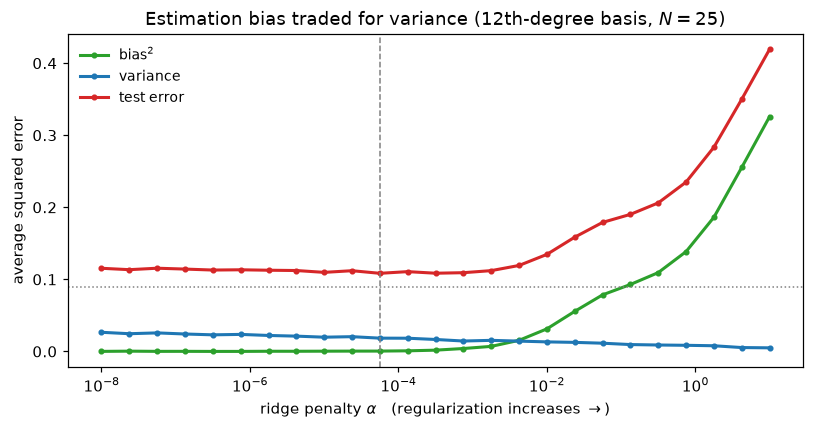

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4))

ax.semilogx(alphas, ridge_bias, "o-", ms=3, color="tab:green", lw=2, label=r"bias$^2$")
ax.semilogx(alphas, ridge_var, "o-", ms=3, color="tab:blue", lw=2, label="variance")
ax.semilogx(alphas, ridge_err, "o-", ms=3, color="tab:red", lw=2, label="test error")
ax.axhline(sigma ** 2, color="gray", ls=":", lw=1)
ax.axvline(best_alpha, color="gray", ls="--", lw=1)

ax.set_xlabel(r"ridge penalty $\alpha$   (regularization increases $\rightarrow$)")
ax.set_ylabel("average squared error")
ax.legend(frameon=False, fontsize=9)
ax.set_title(r"Estimation bias traded for variance (12th-degree basis, $N=25$)")
fig.tight_layout()

On the left ($\alpha\to0$, essentially OLS) the variance dominates; on the right the
coefficients are shrunk too hard and the *estimation* bias takes over. The floor reached at
the right end is the model bias of a 9th-degree polynomial plus the irreducible noise —
no $\alpha$ can remove it.

This is the practical answer to "why does regularization help?" It does not make the model
more correct; it makes it **less sensitive to the training sample**.
[Linear Regression, Part 1](Linear-Regression-Part1.ipynb) showed the same effect on a real
dataset (bicycle traffic); lasso does the same while also selecting features.

## 6. Classification: the error is *not* bias$^2$ + variance

Everything above used squared error. For classification with 0–1 loss the decomposition
breaks: prediction error is no longer the sum of squared bias and variance. ESL §7.3.1
explains why with a one-line argument:

> Suppose at some input the true probability of class 1 is $0.9$, while the expected value
> of our estimate is $0.6$. The squared bias is $(0.6-0.9)^2=0.09$ — considerable — but the
> prediction error is **zero**, because we still classify to class 1.

Errors that keep us on the correct side of the decision boundary cost nothing, so bias and
variance *interact* under 0–1 loss. The best complexity for classification can therefore
differ substantially from the best complexity for squared error.

The experiment below makes this visible with a $k$-NN classifier on a two-dimensional
problem whose posterior is known.

In [14]:
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(7)

p_true = lambda X: np.where(X[:, 0] + X[:, 1] > 0, 0.9, 0.1)

n_tr_c, n_te_c, n_rep_c = 1000, 2000, 100
X_tr = rng.uniform(-1, 1, size=(n_tr_c, 2))
X_te = rng.uniform(-1, 1, size=(n_te_c, 2))
p_te = p_true(X_te)
y_te = (rng.uniform(size=n_te_c) < p_te).astype(int)      # fixed test labels

ks_c = np.array([1, 3, 5, 9, 15, 25, 41, 61, 101, 151])
bias_c, var_c, err_c = [], [], []

for k in ks_c:
    P = np.empty((n_rep_c, n_te_c))
    errors = 0.0
    for r in range(n_rep_c):
        y_tr = (rng.uniform(size=n_tr_c) < p_true(X_tr)).astype(int)
        clf = KNeighborsClassifier(n_neighbors=int(k)).fit(X_tr, y_tr)
        P[r] = clf.predict_proba(X_te)[:, 1]
        errors += np.mean(clf.predict(X_te) != y_te)

    mp = P.mean(axis=0)
    bias_c.append(np.mean((mp - p_te) ** 2))
    var_c.append(np.mean((P - mp) ** 2))
    err_c.append(errors / n_rep_c)

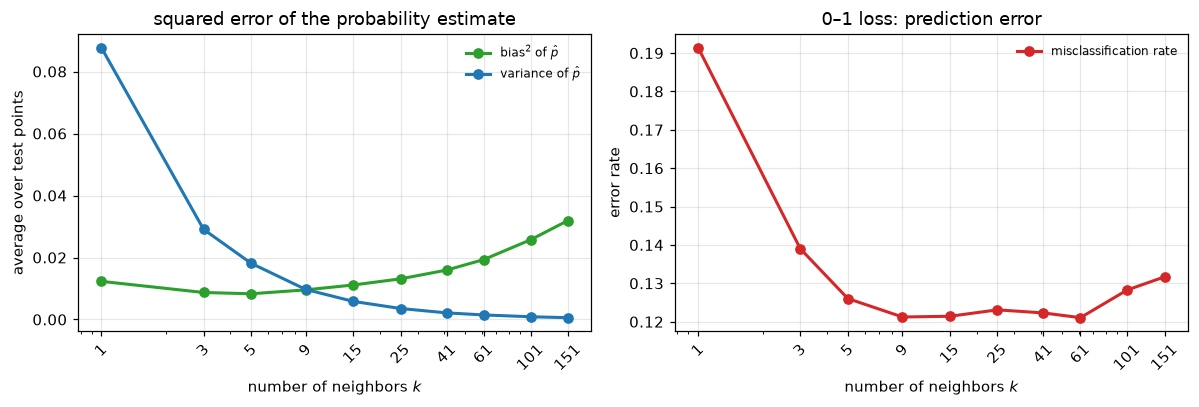

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].semilogx(ks_c, bias_c, "o-", color="tab:green", lw=2, label=r"bias$^2$ of $\hat p$")
axes[0].semilogx(ks_c, var_c, "o-", color="tab:blue", lw=2, label=r"variance of $\hat p$")
axes[0].set_title("squared error of the probability estimate")
axes[0].set_ylabel("average over test points")

axes[1].semilogx(ks_c, err_c, "o-", color="tab:red", lw=2, label="misclassification rate")
axes[1].set_title("0–1 loss: prediction error")
axes[1].set_ylabel("error rate")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(ks_c)
    ax.set_xticklabels([str(k) for k in ks_c], rotation=45)
    ax.set_xlabel(r"number of neighbors $k$")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=0.3)

fig.tight_layout()

In [16]:
print(f"{'k':>5}{'bias^2(p)':>11}{'var(p)':>9}{'sum':>9}{'misclass':>10}")
for i, k in enumerate(ks_c):
    print(f"{k:5d}{bias_c[i]:11.4f}{var_c[i]:9.4f}{bias_c[i] + var_c[i]:9.4f}{err_c[i]:10.4f}")

    k  bias^2(p)   var(p)      sum  misclass
    1     0.0123   0.0877   0.1000    0.1914
    3     0.0087   0.0291   0.0378    0.1390
    5     0.0083   0.0181   0.0264    0.1260
    9     0.0096   0.0097   0.0193    0.1212
   15     0.0111   0.0058   0.0170    0.1214
   25     0.0131   0.0035   0.0167    0.1231
   41     0.0159   0.0021   0.0181    0.1223
   61     0.0193   0.0015   0.0208    0.1211
  101     0.0257   0.0009   0.0266    0.1283
  151     0.0319   0.0006   0.0325    0.1317


Compare the two panels. From $k=5$ to $k=151$ the squared bias of the estimated probability
nearly quadruples ($0.008\to0.032$) and its variance collapses, yet the misclassification
rate stays between $0.121$ and $0.132$ — it even *falls* from $0.126$ at $k=5$ to $0.121$
at $k=61$. Prediction error is no longer controlled by bias$^2$+variance, because the
estimates remain on the correct side of $0.5$. Minimizing "bias$^2$+variance"
would therefore pick the wrong hyperparameter for a classifier — which is why models are
tuned on the metric we actually care about (accuracy, F1, AUC, NDCG, …), as discussed in
[Model Evaluation](Model-Evaluation.ipynb).

## 7. Why the training error is optimistic: optimism, $C_p$ and AIC

Define the *in-sample* error at the training inputs, with **fresh** responses $Y^0_i$ at the
same $x_i$:

$$
\mathrm{Err}_{\text{in}}=\frac{1}{N}\sum_{i=1}^{N}E_{Y^0}\big[L(Y_i^0,\hat f(x_i))\,\big|\,\mathcal T\big],
\qquad
\mathrm{op}\equiv \mathrm{Err}_{\text{in}}-\overline{\mathrm{err}},
\qquad
\omega\equiv E_{\mathcal T}[\mathrm{op}]
\qquad(7.18\text{–}7.20)
$$

For squared error — and, with the right translation, for 0–1 and log-likelihood losses —
the average optimism has a strikingly simple form:

$$
\omega=\frac{2}{N}\sum_{i=1}^{N}\operatorname{Cov}(\hat y_i,y_i),
\qquad
E_{\mathcal T}[\mathrm{Err}_{\text{in}}]=E_{\mathcal T}[\overline{\mathrm{err}}]+\frac{2}{N}\sum_i\operatorname{Cov}(\hat y_i,y_i)
\qquad(7.21\text{–}7.22)
$$

The harder the fit adapts to each $y_i$, the larger this covariance, hence the larger the
optimism. For a linear fit with $d$ parameters,
$\sum_i\operatorname{Cov}(\hat y_i,y_i)=d\sigma_\varepsilon^{2}$, so

$$
E[\mathrm{Err}_{\text{in}}]=E[\overline{\mathrm{err}}]+2\,\frac{d}{N}\sigma_\varepsilon^{2},
\qquad
C_p=\overline{\mathrm{err}}+2\,\frac{d}{N}\hat\sigma_\varepsilon^{2}
\qquad(7.24\text{–}7.26)
$$

and AIC is the log-likelihood version, $-\frac{2}{N}\log\mathrm{lik}+2\frac{d}{N}$ (7.29).
These are *analytic* corrections for the optimism. Cross-validation and the bootstrap, by
contrast, estimate $\mathrm{Err}$ *directly* and need neither linearity nor a known $d$ —
which is why they are the default in practice
(see [Model Evaluation](Model-Evaluation.ipynb)).

Let us verify (7.24) with the polynomial experiment: for each degree compute the training
error, the in-sample error with fresh responses, and compare their difference with
$2d\sigma_\varepsilon^2/N$, where $d=$ degree $+\,1$.

In [17]:
err_in_mean, optimism, predicted_optimism = [], [], []

for i, degree in enumerate(DEGREES):
    e_in = 0.0
    for beta in theta_hat[degree]:
        y_new = f(x_train) + NOISE_STD * np.random.randn(n_train)   # same x, new y
        e_in += np.mean(squared_error(np.polyval(beta, x_train), y_new))
    err_in_mean.append(e_in / len(theta_hat[degree]))

    d = degree + 1                       # number of estimated coefficients
    optimism.append(err_in_mean[i] - mean_train_err[i])
    predicted_optimism.append(2 * d * SIGMA2 / n_train)

print(f"{'degree':>7}{'train err':>11}{'Err_in':>9}{'optimism':>10}{'2 d s^2/N':>11}")
for i, degree in enumerate(DEGREES):
    print(f"{degree:7d}{mean_train_err[i]:11.4f}{err_in_mean[i]:9.4f}"
          f"{optimism[i]:10.4f}{predicted_optimism[i]:11.4f}")

 degree  train err   Err_in  optimism  2 d s^2/N
      1     0.4226   0.4752    0.0526     0.0500
      2     0.3980   0.4787    0.0807     0.0750
      3     0.2047   0.2994    0.0946     0.1000
      4     0.1912   0.3186    0.1275     0.1250
      5     0.1741   0.3215    0.1475     0.1500
      6     0.1614   0.3376    0.1762     0.1750
      7     0.1487   0.3546    0.2059     0.2000
      8     0.1357   0.3635    0.2279     0.2250
      9     0.1230   0.3803    0.2573     0.2500
     10     0.1108   0.3861    0.2753     0.2750
     11     0.0984   0.4078    0.3095     0.3000
     12     0.0862   0.4153    0.3291     0.3250


The measured optimism tracks $2d\sigma_\varepsilon^2/N$ closely, and both grow with the
number of coefficients. Two practical consequences:

1. Comparing models by training error rewards complexity without limit, because the
   optimism grows linearly in $d$ — the comparison is guaranteed to be wrong.
2. Analytic criteria such as $C_p$, AIC and BIC repair exactly this bias, but only under
   their assumptions (a linear fit with a known or estimable $d$, and large $N$ for AIC).
   For adaptive methods — $k$-NN, trees, boosting, neural networks — $d$ is not even
   defined, and we fall back on CV/bootstrap.

## 8. What to do in practice

* **Never select a model by its training error.** The gap is systematic and grows with
  capacity (Section 7).
* **Estimate the error you will actually suffer**, with a protocol matched to the data
  (plain, stratified, grouped or time-series CV) — see
  [Model Evaluation](Model-Evaluation.ipynb).
* **Use regularization as the bias–variance dial.** Tune $\alpha$ (or the number of
  neighbors, the depth, the number of components) on a logarithmic grid with CV, as in
  Section 5.
* **More data helps variance, not model bias.** Variance falls roughly like $1/N$; a family
  that cannot represent the truth keeps its bias however much data arrives. Adaptive
  methods also shrink their bias with more data, because the neighborhood or leaf can
  become smaller.
* **The one-standard-error rule** (ESL §7.10): among models within one standard error of the
  best CV score, pick the simplest. It sits on the flat part of the curve and is less likely
  to be a lucky draw.
* **Classification is not regression.** Optimize the loss you are evaluated on; the
  decomposition is not additive for 0–1 loss (Section 6).
* **Beware the double-descent regime.** With heavily overparameterized models
  ($p\gg N$, modern networks) the test error can fall again after the interpolation
  threshold. The classical U-curve describes the *restricted* regime; see the further
  reading below.

## Exercises

1. **Analytic $k$-NN.** Take a linear $f(x)=ax$ and a fixed design. Starting from (7.10),
   show that the bias term is proportional to $(k/N)^2$ and the variance to $1/k$, then
   derive the optimal $k$ and its rate in $N$.
2. **Effective degrees of freedom of ridge.** With the SVD $X=UDV^{T}$ write the ridge fit
   as $\hat f_\alpha=H_\alpha y$ and show $\operatorname{tr}(H_\alpha)=\sum_j d_j^2/(d_j^2+\alpha)\le p$;
   interpret it as the $d$ that enters (7.24).
3. **Optimism by simulation.** Repeat Section 7 for $k$-NN regression. Verify empirically
   that the optimism is *not* $2d\sigma^2/N$ for any integer $d$, and explain why
   (hint: replace $d$ by the effective degrees of freedom of Exercise 2).
4. **0–1 loss.** Repeat the argument of ESL §7.3.1 for a three-class problem and construct a
   case where increasing $k$ increases the squared bias of all three probabilities but
   leaves the error rate unchanged.
5. **Double descent.** Fit polynomial regressions of degree up to $N$ on $N=20$ points and
   plot test error against the number of parameters. Where is the interpolation threshold,
   and what happens to the variance just after it?
6. **Model-bias floor.** Fit a degree-1 model to $f(x)=\sin(\pi x)$ with $N\to\infty$. Show
   numerically that the error converges to the squared model bias plus
   $\sigma_\varepsilon^2$, and compute that limit analytically.

## References

* Hastie, Tibshirani and Friedman, *The Elements of Statistical Learning*, 2nd ed.:
  §7.2 (bias, variance and model complexity), §7.3 (the decomposition and Example 7.3.1),
  §7.4–7.5 (optimism, $C_p$, AIC), §7.10 (cross-validation, one-standard-error rule),
  Figures 7.1–7.3.
* James, Witten, Hastie and Tibshirani, *An Introduction to Statistical Learning*,
  §2.2.3 — the same trade-off in a lighter form.
* Geman, Bienenstock and Doursat (1992), *Neural Computation* 4(1) — the original
  bias/variance decomposition for learning systems.
* Belkin, Hsu and Xu (2019), *Reconciling modern machine-learning practice and the
  classical bias–variance trade-off* — the double-descent view.
* [Bias–variance tradeoff (Wikipedia)](https://en.wikipedia.org/wiki/Bias%E2%80%93variance_tradeoff)
* [MLU-Explain: bias–variance](https://mlu-explain.github.io/bias-variance/) and
  [double descent](https://mlu-explain.github.io/double-descent/)
* scikit-learn: [validation curves](https://scikit-learn.org/stable/modules/learning_curve.html)
  and [learning curves](https://scikit-learn.org/stable/modules/learning_curve.html#learning-curve).